# Experiment: KMeans Clustering
---



## Objective
---

- Implement KMeans Clustering algorithm to find customer segements in the unlabeled Mall dataset.



## Setup
---
Imports and Configuration

In [248]:
print("🔃 importing modules...")
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# Set aesthetics
sns.set_theme(
    style='whitegrid',
    font="DejaVu Sans",       # clean, readable sans-serif (works cross-platform)
    font_scale=1.1,           # slightly larger text overall
)


print("✅ Modules imported. ")

🔃 importing modules...
✅ Modules imported. 


## Data
---
### Load and Inspect

In [249]:
df = pd.read_csv("./Mall_Customers.csv")

df.head()

,CustomerID,Genre,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


In [250]:
# Shape of dataset
print("Shape: ", df.shape)

Shape:  (200, 5)


In [251]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype
---  ------                  --------------  -----
 0   CustomerID              200 non-null    int64
 1   Genre                   200 non-null    str  
 2   Age                     200 non-null    int64
 3   Annual Income (k$)      200 non-null    int64
 4   Spending Score (1-100)  200 non-null    int64
dtypes: int64(4), str(1)
memory usage: 8.9 KB


In [252]:
# Statistical Overview
df.describe()

,CustomerID,Age,Annual Income (k$),Spending Score (1-100)
count,200.000000,200.000000,200.000000,200.000000
mean,100.500000,38.850000,60.560000,50.200000
std,57.879185,13.969007,26.264721,25.823522
min,1.000000,18.000000,15.000000,1.000000
25%,50.750000,28.750000,41.500000,34.750000
50%,100.500000,36.000000,61.500000,50.000000
75%,150.250000,49.000000,78.000000,73.000000
max,200.000000,70.000000,137.000000,99.000000


In [253]:
df.isna().sum()

CustomerID                0
Genre                     0
Age                       0
Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64

### Clean Dataset

In [254]:
# Removing whitespaces

# columns = []

# for col in df.columns.to_list():
#     col = col.replace(' ', '')
#     print(col)
#     columns.append(col)
    
# df.columns = columns
# df.columns

# OR
df.columns = df.columns.str.replace(' ', '')
df.columns


Index(['CustomerID', 'Genre', 'Age', 'AnnualIncome(k$)',
       'SpendingScore(1-100)'],
      dtype='str')

In [255]:
df.head()

,CustomerID,Genre,Age,AnnualIncome(k$),SpendingScore(1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


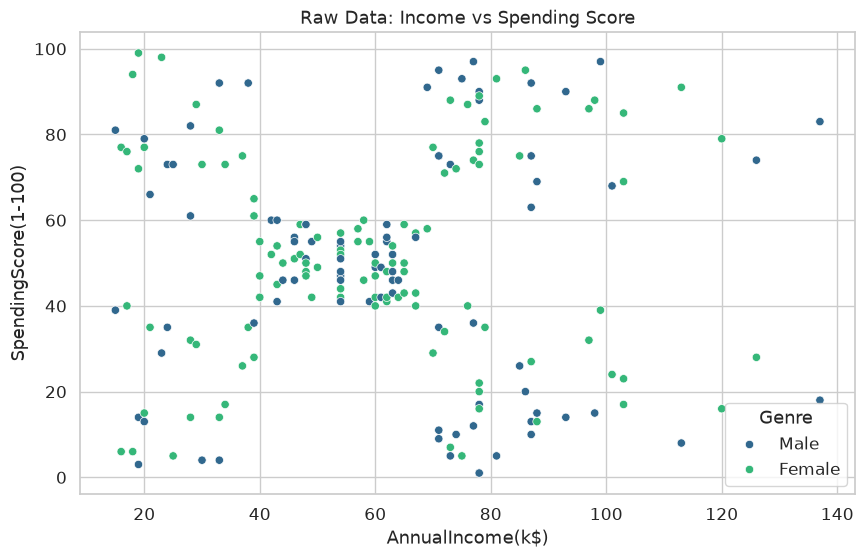

In [256]:
sns.scatterplot(
    data=df, 
    x='AnnualIncome(k$)', 
    y='SpendingScore(1-100)',
    hue='Genre',
    palette='viridis',
)

plt.title('Raw Data: Income vs Spending Score')
plt.show()

In [257]:
# Manually Encode Genre
df['Genre_encoded'] = df['Genre'].map(
    {
        "Female": 0,
        "Male": 1
    }
)

df['Genre_encoded'].head()

0    1
1    1
2    0
3    0
4    0
Name: Genre_encoded, dtype: int64

In [258]:
# Drop the Genre
df_mall = df.copy()

df_mall = df_mall.drop(columns=['CustomerID', 'Genre'])

In [259]:
# Define Features 
features = df_mall.columns.to_list()
features

['Age', 'AnnualIncome(k$)', 'SpendingScore(1-100)', 'Genre_encoded']

In [260]:
X = df_mall[features].values
X

array([[ 19,  15,  39,   1],
       [ 21,  15,  81,   1],
       [ 20,  16,   6,   0],
       [ 23,  16,  77,   0],
       [ 31,  17,  40,   0],
       [ 22,  17,  76,   0],
       [ 35,  18,   6,   0],
       [ 23,  18,  94,   0],
       [ 64,  19,   3,   1],
       [ 30,  19,  72,   0],
       [ 67,  19,  14,   1],
       [ 35,  19,  99,   0],
       [ 58,  20,  15,   0],
       [ 24,  20,  77,   0],
       [ 37,  20,  13,   1],
       [ 22,  20,  79,   1],
       [ 35,  21,  35,   0],
       [ 20,  21,  66,   1],
       [ 52,  23,  29,   1],
       [ 35,  23,  98,   0],
       [ 35,  24,  35,   1],
       [ 25,  24,  73,   1],
       [ 46,  25,   5,   0],
       [ 31,  25,  73,   1],
       [ 54,  28,  14,   0],
       [ 29,  28,  82,   1],
       [ 45,  28,  32,   0],
       [ 35,  28,  61,   1],
       [ 40,  29,  31,   0],
       [ 23,  29,  87,   0],
       [ 60,  30,   4,   1],
       [ 21,  30,  73,   0],
       [ 53,  33,   4,   1],
       [ 18,  33,  92,   1],
       [ 49,  

### Preprocessing

In [261]:
# Scale the features

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
X_scaled

array([[-1.42456879, -1.73899919, -0.43480148,  1.12815215],
       [-1.28103541, -1.73899919,  1.19570407,  1.12815215],
       [-1.3528021 , -1.70082976, -1.71591298, -0.88640526],
       [-1.13750203, -1.70082976,  1.04041783, -0.88640526],
       [-0.56336851, -1.66266033, -0.39597992, -0.88640526],
       [-1.20926872, -1.66266033,  1.00159627, -0.88640526],
       [-0.27630176, -1.62449091, -1.71591298, -0.88640526],
       [-1.13750203, -1.62449091,  1.70038436, -0.88640526],
       [ 1.80493225, -1.58632148, -1.83237767,  1.12815215],
       [-0.6351352 , -1.58632148,  0.84631002, -0.88640526],
       [ 2.02023231, -1.58632148, -1.4053405 ,  1.12815215],
       [-0.27630176, -1.58632148,  1.89449216, -0.88640526],
       [ 1.37433211, -1.54815205, -1.36651894, -0.88640526],
       [-1.06573534, -1.54815205,  1.04041783, -0.88640526],
       [-0.13276838, -1.54815205, -1.44416206,  1.12815215],
       [-1.20926872, -1.54815205,  1.11806095,  1.12815215],
       [-0.27630176, -1.

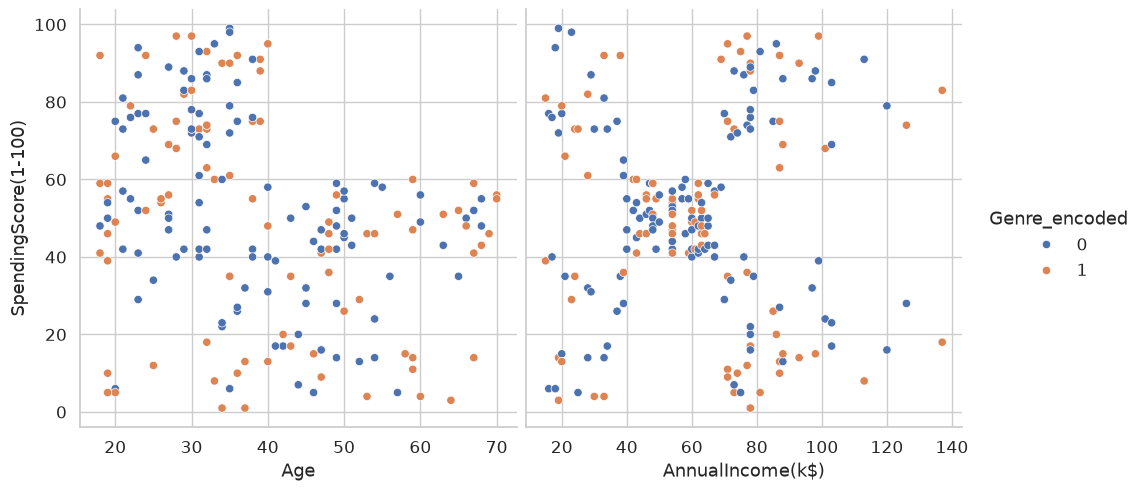

In [262]:
# Plot the pairplot diagram of the dataset
sns.pairplot(
    df_mall,
    y_vars=['SpendingScore(1-100)'],
    x_vars=['Age', 'AnnualIncome(k$)'],
    hue='Genre_encoded',
    height=5,
)
plt.show()


We can instantly notice 5 clusters from the pairplot. This means that our choice of k would be k=5. However, in general this isnt easy.


## Experiment
---
### Selecting initial K

In [263]:
# Applying clusters.
k = 5
kmeans = KMeans(n_clusters=k, random_state=42, init='random')   # init='random' makes the algorithm run for 10 times
y_pred = kmeans.fit_predict(X_scaled)
y_pred

array([0, 0, 0, 0, 0, 0, 4, 0, 3, 0, 3, 0, 4, 0, 3, 0, 0, 0, 3, 0, 3, 0,
       4, 0, 4, 0, 4, 0, 4, 0, 3, 0, 3, 0, 4, 0, 4, 0, 4, 0, 4, 0, 3, 0,
       4, 0, 4, 0, 0, 0, 4, 0, 0, 3, 4, 3, 4, 3, 0, 3, 3, 0, 4, 4, 3, 0,
       4, 4, 0, 0, 3, 4, 4, 4, 3, 0, 4, 3, 0, 4, 3, 3, 3, 4, 0, 3, 4, 0,
       0, 4, 4, 0, 3, 4, 4, 0, 4, 0, 3, 0, 0, 4, 3, 0, 3, 0, 4, 3, 3, 3,
       3, 0, 4, 0, 0, 0, 4, 4, 4, 4, 0, 4, 4, 1, 0, 1, 2, 1, 3, 1, 2, 1,
       0, 1, 2, 1, 4, 1, 2, 1, 4, 1, 4, 1, 2, 1, 2, 1, 4, 1, 2, 1, 4, 1,
       4, 1, 2, 1, 2, 1, 4, 1, 2, 1, 2, 1, 2, 1, 4, 1, 2, 1, 2, 1, 4, 1,
       2, 1, 2, 1, 2, 1, 2, 1, 4, 1, 4, 1, 2, 1, 2, 1, 2, 1, 2, 1, 2, 1,
       2, 1], dtype=int32)

The KMeans instance preserves a copy of the labels of the instances it was trained on. This is available via the `labels_` instance attribute

In [264]:
y_pred is kmeans.labels_

True

Inspecting the 5 centroids found by the algorithm

In [265]:
kmeans.cluster_centers_

array([[-1.00293949, -0.7547732 ,  0.38599723, -0.13094623],
       [-0.44191719,  0.99158305,  1.23950275,  0.04339047],
       [ 0.00777472,  1.15710625, -1.32446225,  0.70845269],
       [ 1.23079873, -0.50739895, -0.4128026 ,  1.12815215],
       [ 0.71154562, -0.17554944, -0.50559374, -0.88640526]])

- The array has 5 rows corresponding to the 5 clusters configuration
- 4 columns represent the number of features. 
- The numbers are  the coordinates of the center of each cluster. For example, the first cluster's center is at coordinates: (`-1.00293949, -0.7547732 ,  0.38599723, -0.13094623`)
- Note: _The negative numbers indicate that the training data was standardized (scaled), which is a common and highly recommended practice for K-Means._

### Predicting New Instances

- Since our model was trained on data with 4 features, any new instances you want to predict must also have exactly 4 features. 
- The new instances must be scaled as well
- We need to create a 2D numpy array.

In [266]:
# New instances, each with 4 features

X_new = np.array(
    [
        [50.0, 30.0, 40.0, 0.5],
        [25.0, 85.0, 75.0, 0.4],
        [45.0, 25.0, 20.0, 0.3],
    ]
)

# Scale new data: transform() for new, test data
X_new_scaled = scaler.transform(X_new)
X_new_scaled


array([[ 0.80019859, -1.16645776, -0.39597992,  0.12087344],
       [-0.99396865,  0.93286085,  0.96277471, -0.0805823 ],
       [ 0.44136514, -1.3573049 , -1.17241113, -0.28203804]])

In [267]:
# # Make predictions
predictions = kmeans.predict(X_new_scaled)
predictions

array([3, 1, 4], dtype=int32)

From the new results, 
- first instance     → cluter 4, 
- second instance    → cluter 2, 
- third instance     → cluter 5, 

### Inertia and score

In [268]:
kmeans.inertia_, kmeans.score(X_scaled)

(333.26367023336877, -333.2636702333687)

### KMeans++ initialization Algorithm

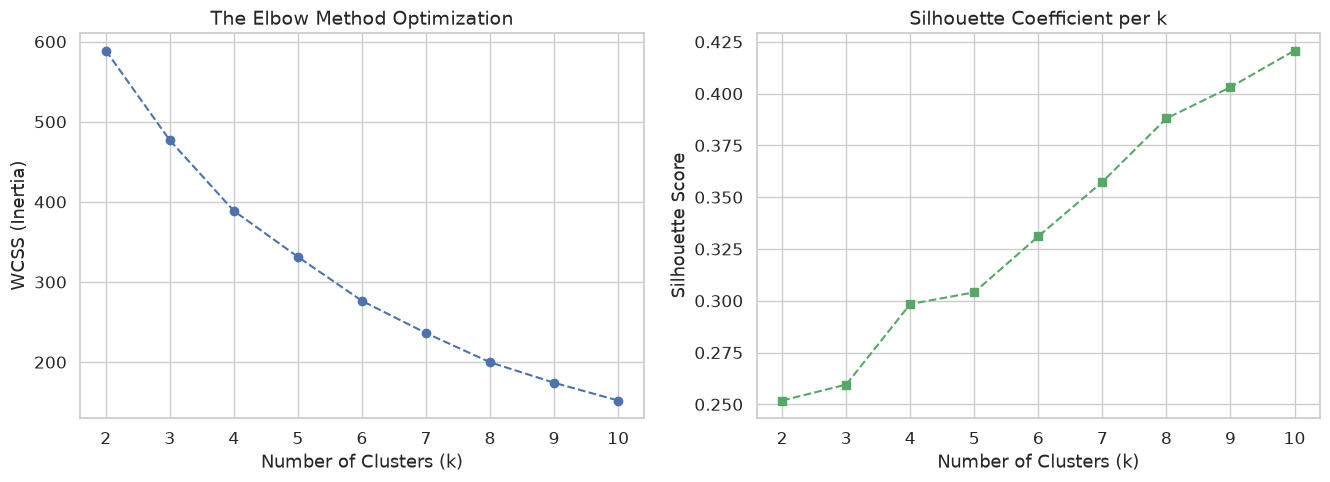

In [269]:
# Optimal Clusters

wcss = []
sihoulette_scores = []
k_range = range(2,11)

for k in k_range:
    kmeans = KMeans(n_clusters=k, init='k-means++', random_state=42, n_init=10)
    kmeans.fit(X_scaled)
    wcss.append(kmeans.inertia_)
    sihoulette_scores.append(silhouette_score(X_scaled, kmeans.labels_))


# Set plot aesthetics
# sns.set_theme(style='whitegrid')
plt.rcParams['figure.figsize'] = (10,6)


# Define the axes for boths plots
fig, ax = plt.subplots(1,2, figsize=(16,5))

# Plot the Elbow Curve
ax[0].plot(range(2,11), wcss, marker = 'o', linestyle='--', color ='b')
ax[0].set_title('The Elbow Method Optimization', fontsize=14)
ax[0].set_xlabel('Number of Clusters (k)')
ax[0].set_ylabel('WCSS (Inertia)')

# Sihlouette Score
ax[1].plot(range(2,11), sihoulette_scores, marker = 's', linestyle='--', color ='g')
ax[1].set_title('Silhouette Coefficient per k', fontsize=14)
ax[1].set_xlabel('Number of Clusters (k)')
ax[1].set_ylabel('Silhouette Score')

# Show the plot
plt.show()

We can see that the curve makes a noticeable bend (elbow) at k=5. So we our optimal k=5

In [270]:
optimal_k = 5

# Model Training
kmeans_new = KMeans(n_clusters=optimal_k, init='k-means++', random_state=42, n_init=10)
cluster_labels = kmeans_new.fit_predict(X_scaled)

# Append cluster labels back to the dataframe
df_mall['Cluster'] = cluster_labels
df_mall.head()


,Age,AnnualIncome(k$),SpendingScore(1-100),Genre_encoded,Cluster
0,19,15,39,1,3
1,21,15,81,1,3
2,20,16,6,0,3
3,23,16,77,0,3
4,31,17,40,0,3


In [271]:
kmeans_new.inertia_, kmeans_new.cluster_centers_

(331.3098837641086,
 array([[-0.44191719,  0.99158305,  1.23950275,  0.04339047],
        [-0.16988908,  1.10528137, -1.25005425,  0.0166722 ],
        [ 0.78684665, -0.43236199, -0.39327144, -0.88640526],
        [-1.00061372, -0.79536608,  0.42718095, -0.06565965],
        [ 1.21029396, -0.26238756, -0.5213181 ,  1.12815215]]))

In [272]:
df_mall.tail(20)

,Age,AnnualIncome(k$),SpendingScore(1-100),Genre_encoded,Cluster
180,37,97,32,0,1
181,32,97,86,0,0
182,46,98,15,1,1
183,29,98,88,0,0
184,41,99,39,0,1
185,30,99,97,1,0
186,54,101,24,0,1
187,28,101,68,1,0
188,41,103,17,0,1
189,36,103,85,0,0


In [273]:
# Check the count of clusters
df_mall['Cluster'].value_counts().reset_index()

,Cluster,count
0,3,54
1,2,43
2,0,39
3,4,35
4,1,29


In [274]:
# Post Cluster Visualization
plt.figure(figsize=(11,7))


# Define the profiless for the distinct labels

cluster_profiles = {
    0 : 'Target Market (High Income, High Spend)',
    1 : 'Affluent Conservatists (High Income, Low Spend)',
    2 : 'Frugal/Under-resiurced (Low Income, Low Spend)',
    3 : 'Carefree Spenders (Low Income, High Spend)',
    4 : 'Sensible Middle (Mid Income, Mid Spend)',
}


df_mall['Cluster_Profile'] = df_mall['Cluster'].map(cluster_profiles
)

df_mall.head()

,Age,AnnualIncome(k$),SpendingScore(1-100),Genre_encoded,Cluster,Cluster_Profile
0,19,15,39,1,3,"Carefree Spenders (Low Income, High Spend)"
1,21,15,81,1,3,"Carefree Spenders (Low Income, High Spend)"
2,20,16,6,0,3,"Carefree Spenders (Low Income, High Spend)"
3,23,16,77,0,3,"Carefree Spenders (Low Income, High Spend)"
4,31,17,40,0,3,"Carefree Spenders (Low Income, High Spend)"


<Figure size 1100x700 with 0 Axes>

In [275]:
df_mall.columns.to_list()

['Age',
 'AnnualIncome(k$)',
 'SpendingScore(1-100)',
 'Genre_encoded',
 'Cluster',
 'Cluster_Profile']

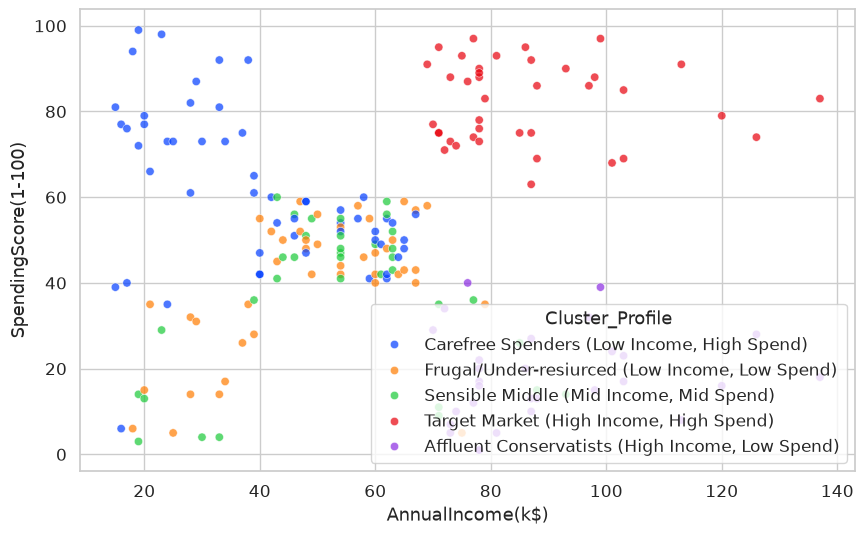

In [276]:
# Plot The Scatterplot

# markers = {
#     0 : 'Target Market (High Income, High Spend)',
#     1 : 'Affluent Conservatists (High Income, Low Spend)',
#     2 : 'Frugal/Under-resiurced (Low Income, Low Spend)',
#     3 : 'Carefree Spenders (Low Income, High Spend)',
#     4 : 'Sensible Middle (Mid Income, Mid Spend)',
# }


markers = {
    'Carefree Spenders (Low Income, High Spend)': "x",
    'Sensible Middle (Mid Income, Mid Spend)': "o",
}




sns.scatterplot(
    data=df_mall,
    x='AnnualIncome(k$)',
    y='SpendingScore(1-100)',
    hue='Cluster_Profile',
    palette='bright',
    # size='Cluster_Profile',
    markers="=",
    # edgecolor='black',
    alpha=0.7,
)
plt.show()


## Result
---

## Interpretation
---

What happened and why?

## Key Takeaways
---